# Retrieval example

One stored dynesty retrieval in detail: data and likelihood, the posteriors and Bayes factors of the three insolation models, the posterior predictive, the bias against the noiseless fit, and the derived temperatures and depths. It reads one of the three TOI-2431 b retrievals in `example_runs/` (`EXAMPLES`); runs of `run_dynesty.py` in `dynesty_results/` are selected the same way (`find_dataset`). Each pickle carries its data, priors, truth and `FittingConfig`, and `logl_from_fit` rebuilds the likelihood, warning if the forward model has changed since the run.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hyperphase.model import model_pcurve, pcurve_params
from hyperphase.phasecurve import occultation_depth
from hyperphase.bias.detectors import detector_cfgs
from hyperphase.plotting.retrieval import (plot_bias, plot_derived, plot_noisy_vs_truth, plot_posterior_overlay, plot_posterior_predictive,
                                           plot_simulated_data)
from hyperphase.retrieval.likelihood import derived_samples, grid_max, logl_grid, logl_slice
from hyperphase.retrieval.sampler import bayes_factor, brightness_temperature, equal_samples, posterior_summary
from hyperphase.retrieval.storage import check_datasets, find_dataset, load_fits, logl_from_fit
from dynesty import utils as dyfunc, plotting as dyplot
from dataclasses import replace
import os

N_JOBS = -1      # forward models run process-parallel (loky); the plots below are the only likelihood cost
INSOL_REF = "hyperillum"   # the model the data were drawn from: always fitted, so it is the reference for the shared (A_B, offset) box and the numerator of every Bayes factor
COLOR  = {"naive": "C0", "hyperillum": "C3", "naive_redist": "C2"}

In [2]:
# --- load data file ---------------------------------------------------------------------------------------
RESULTS_DIR = "example_runs"   # the three retrievals shipped with the repository; run_dynesty.py writes new runs to "dynesty_results"

# An entry names only what deviates from the defaults: the baseline settings of hyperphase.defaults, seed 42 and pfrac 0.8 (the sampler's posterior/evidence weighting).
LRS, JOINT = "MIRI/LRS", "JWST_NIRSpec.G395H_joint"
EXAMPLES = {
    "TOI-2431b LRS seed44":               dict(planet="TOI-2431 b", instrument=LRS, seed=44),
    "TOI-2431b joint seed41":             dict(planet="TOI-2431 b", instrument=JOINT, seed=41),
    "TOI-2431b LRS free geometry seed44": dict(planet="TOI-2431 b", instrument=LRS, seed=44, subfolder="free_geometry"),   # a/R*, Rp/R* and b sampled too
}
check_datasets(RESULTS_DIR, EXAMPLES)   # prints the entries without a run and the runs not on the list


#################################################################################
results = "TOI-2431b LRS seed44"
#################################################################################


# The dataset: its tag is everything the models share, so one glob on it picks up every model of the dataset, whatever each was sampled with
# (the files end in _{insolation_model}_priors-...). No or several matches raise with the menu for the planet; list_datasets(RESULTS_DIR) shows all of it.
results_file = find_dataset(RESULTS_DIR, **EXAMPLES[results])
RESULTS = f"{RESULTS_DIR}/{results_file}_*.pkl"

In [3]:
fits  = load_fits(RESULTS)                                    # {insolation_model: NestedFit}; whichever models the pattern found
fits  = {m: fits[m] for m in ("hyperillum", "naive", "naive_redist") if m in fits}   # fixed order, so colours and panels do not depend on how the files happened to sort
logls = {m: logl_from_fit(f) for m, f in fits.items()}        # the likelihood each fit was run with, rebuilt from its own cfg (a JointGaussianLogL for a joint detector fit)

# The models need NOT share a ParameterSet: only "naive_redist" samples F. Everything shared comes from the truth's own model, which is always run.
ref   = fits[INSOL_REF]
pset  = ref.pset                                               # the (A_B, baselines) box every model has - what the grids below are built on
PSETS = {m: f.pset for m, f in fits.items()}                   # what each model was ACTUALLY sampled with
cfg   = ref.meta["cfg"]                                        # one FittingConfig, or the detector set (tuple) of a joint fit
cfgs  = detector_cfgs(cfg); cfg0 = cfgs[0]                     # cfg0 carries everything band-independent (planet, binning)
LABELS = list(ref.meta.get("labels") or [])                    # detector labels of a joint fit ("NRS1", "NRS2"), [] for a single band
JOINT  = len(cfgs) > 1
data  = ref.meta["data"]                                       # per-detector dicts under data["detectors"] for a joint fit
truth = data["truth"]                                          # what simulate_data injected
A_B_true, INSOL_TRUTH = truth["A_B"], truth["insolation_model"]
assert INSOL_TRUTH == INSOL_REF, f"the data were drawn from {INSOL_TRUTH}, but INSOL_REF is {INSOL_REF}"
OFFSET_NAMES = [n for n in pset.names if n.startswith("offset")]   # "offset", or one "offset_<label>" per detector
# the injected value of every parameter ANY model samples. Only a "naive_redist" truth has an F; otherwise the data are drawn without redistribution and F = 0 is the truth for it too.
TRUTH_OF = dict(A_B=A_B_true, F=truth.get("F") if truth.get("F") is not None else 0., **{o: truth["offset"] for o in OFFSET_NAMES},
                a_rs=cfg0.planet.R / cfg0.planet.r2, rp_rs=cfg0.planet.r1 / cfg0.planet.r2, T_s=cfg0.planet.T2_eff,
                incl=cfg0.planet.incl, b=cfg0.planet.R / cfg0.planet.r2 * np.cos(np.radians(cfg0.planet.incl)))   # the geometry is injected at the planet's own values (sampled only in the free_geometry runs)
base  = {n: TRUTH_OF[n] for f in fits.values() for n in f.pset.names}

print(f"{cfg0.planet.name}   truth = {INSOL_TRUTH}, A_B = {A_B_true:g}" + (f", F = {truth['F']:g}" if truth.get("F") is not None else "") + f", offset = {truth['offset']:g} ppm, data seed = {truth['seed']}" + ("   |   JOINT fit of " + " + ".join(LABELS) if JOINT else ""))
for c, lab in zip(cfgs, LABELS or [""]):
    print(f"   {lab:5s} [{c.l1*1e6:.2f}-{c.l2*1e6:.2f} um]  rms_1min = {c.sigma_1min:.1f} ppm -> sigma_bin = {c.sigma_bin:.1f} ppm over {c.n_bins} bins x {c.n_orbits} orbits")
print(f"models: {', '.join(fits)}\n")
print(f"{'model':12s} {'lnZ':>20s} {'ncall':>8s} {'runtime':>9s}   pfrac   status   (ESS is part of the status line; pfrac: the sampler's posterior/evidence weighting)")
for m, f in fits.items():
    print(f"{m:12s} {f.meta['lnZ']:10.4f} +/- {f.meta['lnZ_err']:.4f} {f.meta['ncall']:8d} {f.meta['runtime_s']/60:7.1f} m   {f.scfg.pfrac:5g}   {f.meta['status']}")
    print(f"{'':12s} sampled: {', '.join(f.pset.names)}")
    print(f"{'':12s} {os.path.basename(f.meta.get('file', '(not saved)'))}")

TOI-2431 b   truth = hyperillum, A_B = 0.2, offset = 0 ppm, data seed = 44
         [5.00-10.50 um]  rms_1min = 62.9 ppm -> sigma_bin = 8.1 ppm over 27 bins x 5 orbits
models: hyperillum, naive, naive_redist

model                         lnZ    ncall   runtime   pfrac   status   (ESS is part of the status line; pfrac: the sampler's posterior/evidence weighting)
hyperillum     -94.4082 +/- 0.0545    32790     6.9 m     0.8   CONVERGED | stop 0.985, 9/10 batches, ESS 9135
             sampled: A_B, offset
             TOI-2431b_MIRI-LRS_fixedA0.1_AB0.2_nbins27_norbits5_rms1min62.9_sigmascale1_seed44_pfrac0.8_hyperillum_priors-A_B+offset.pkl
naive         -100.6518 +/- 0.0538    31687     9.7 m     0.8   CONVERGED | stop 0.986, 9/10 batches, ESS 9110
             sampled: A_B, offset
             TOI-2431b_MIRI-LRS_fixedA0.1_AB0.2_nbins27_norbits5_rms1min62.9_sigmascale1_seed44_pfrac0.8_naive_priors-A_B+offset.pkl
naive_redist  -100.8526 +/- 0.0776    43596     8.7 m     0.8   CONVERGED 

## 1. Data and likelihood

$\Delta\ln\mathcal{L} = \ln\mathcal{L} - \ln\mathcal{L}_{\max}$ in 1D slices (every other parameter at the truth; dotted: 1/2/3$\sigma$) and 2D maps (contours: the 2-parameter 1/2/3$\sigma$ levels); with uniform priors the maps preview the posteriors of 2. In the slices `naive_redist` at its injected $F = 0$ is the naive model. In the $(A_B, F)$ map the baselines are profiled out, since they correlate with $F$.

sigma_bin: 8.14 ppm  (bin width 11.96 min)
chi2 / n_bins (normalized average noise per bin ~1): 0.58
residual mean / sigma (~0): 0.12


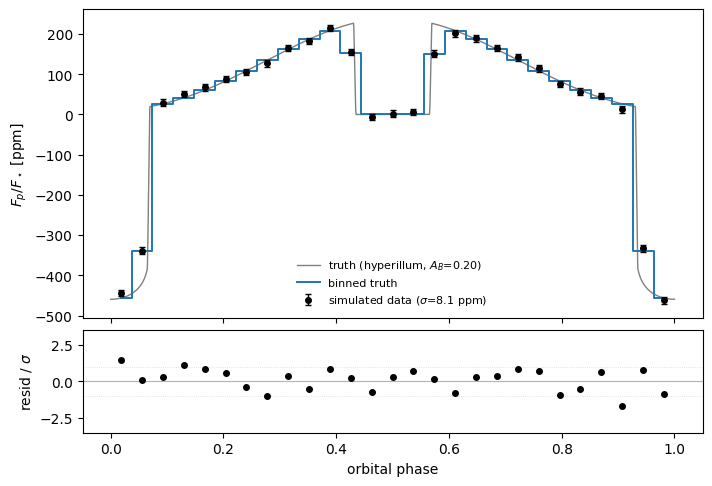

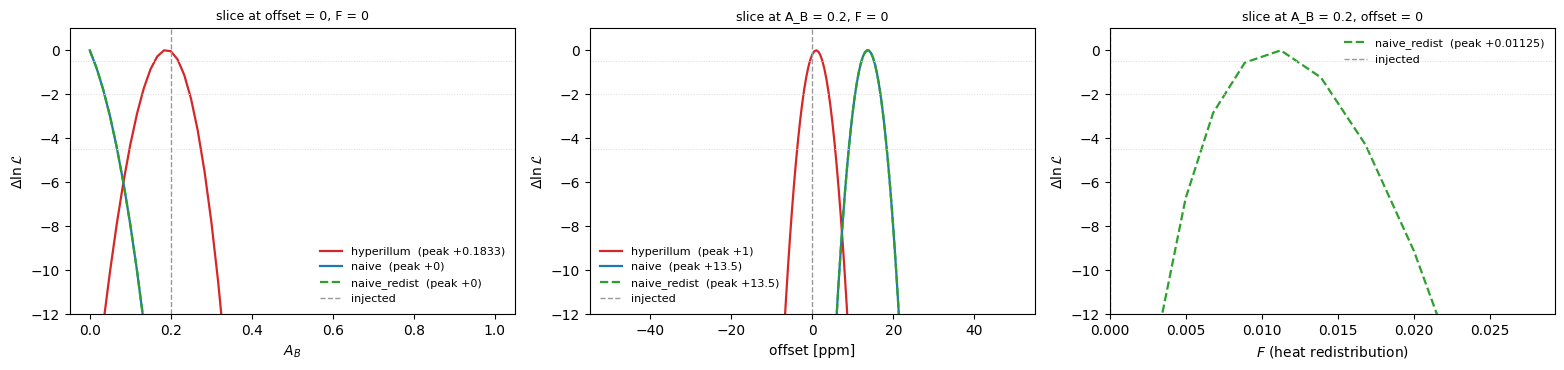

hyperillum   grid MAP: A_B = 0.2167, offset = +1.50 ppm, lnL = -89.042
naive        grid MAP: A_B = 0.1500, offset = +12.00 ppm, lnL = -95.423
naive_redist grid MAP: A_B = 0.1500, offset = +12.00 ppm, lnL = -95.422


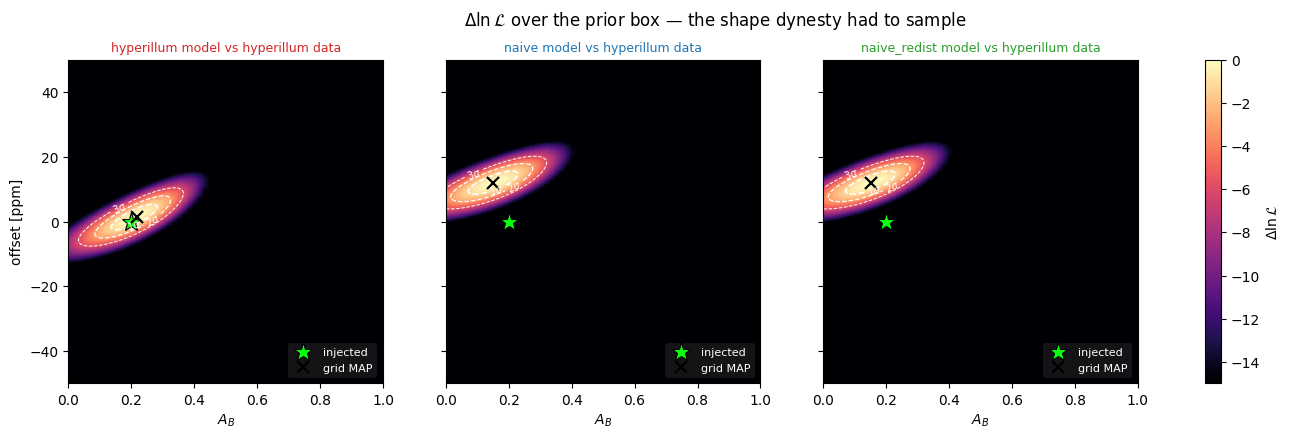

naive_redist grid MAP: A_B = 0.0500, F = 0.0059, lnL = -91.027   (offset profiled out)


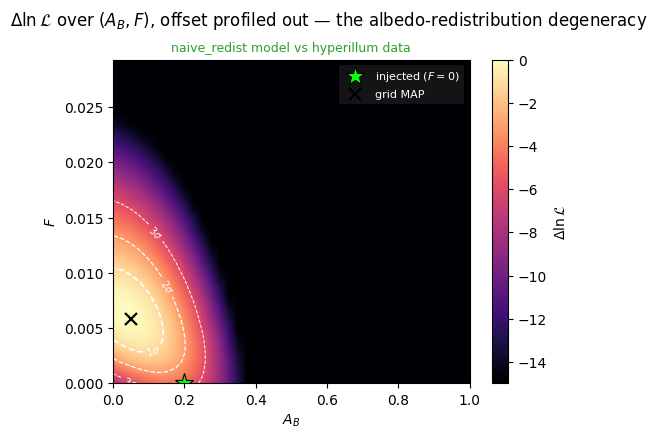

In [4]:
A_grid, O_grid = pset.grid("A_B", 61),  pset.grid(OFFSET_NAMES[0], 201)   # every baseline has the same prior OFFSET_BOUNDS
PLANET = cfg0.planet.name.replace(' ', '')

# the truth curve is re-evaluated here (one forward model per detector), the data points come straight out of the saved fit
plot_simulated_data(cfg, A_B_true, data, insolation_model=INSOL_TRUTH, labels=LABELS or None)
plt.show()

# 1D slices. One panel per parameter ANY model samples - so F gets its own as soon as a "naive_redist" run is loaded,
# and the models that do not sample it simply have no curve there; a joint fit has one baseline panel per detector.
F_MODELS = [m for m in fits if "F" in PSETS[m].names]          # [] when no redistribution run is in this dataset
GRIDS  = {"A_B": A_grid, **{o: O_grid for o in OFFSET_NAMES}}
if F_MODELS:   # F nodes over the full prior but quadratically dense towards 0, where the likelihood sits (the response to F is ~F^1.5 near 0 and the posterior is a sliver of the prior); the panel is zoomed below
    lo_F, hi_F = PSETS[F_MODELS[0]].bounds[PSETS[F_MODELS[0]].names.index("F")]
    GRIDS["F"] = lo_F + (hi_F - lo_F) * np.linspace(0., 1., 61) ** 2
XLABEL = {"A_B": "$A_B$", "F": "$F$ (heat redistribution)", **{o: o.replace("offset_", "offset ") + " [ppm]" for o in OFFSET_NAMES}}
YLIM   = -12.

SLICES = {}
fig, axes = plt.subplots(1, len(GRIDS), figsize=(5.25 * len(GRIDS), 3.8), squeeze=False)
for ax, (p, g) in zip(axes.ravel(), GRIDS.items()):
    for name, L in logls.items():
        if p not in L.names: continue                          # e.g. F, which only "naive_redist" has
        s = logl_slice(L, p, g, base, n_jobs=N_JOBS)           # one forward model per node, except the baselines (additive -> free)
        SLICES[p, name] = s
        # dashed for naive_redist: at the injected F = 0 it IS the naive model, so in the A_B and offset panels the two curves lie exactly on top of each other
        ax.plot(g, s - s.max(), color=COLOR[name], lw=1.6, ls="--" if name == "naive_redist" else "-", label=f"{name}  (peak {g[s.argmax()]:+.4g})")
    for d in (-0.5, -2.0, -4.5):
        ax.axhline(d, color="0.85", lw=0.7, ls=":")
    ax.axvline(base[p], color="0.6", lw=1.0, ls="--", label="injected")
    ax.set_xlabel(XLABEL[p]); ax.set_ylabel(r"$\Delta\ln\mathcal{L}$")
    ax.set_ylim(YLIM, 1.); ax.legend(frameon=False, fontsize=8)
    ax.set_title("slice at " + ", ".join(f"{q} = {base[q]:g}" for q in GRIDS if q != p), fontsize=9)
    if p == "F":   # the F posterior is a sliver against its [0, 0.5] prior, so zoom the axis to where the curve is still on the panel (linear, never sqrt)
        on = np.concatenate([g[(SLICES[p, m] - SLICES[p, m].max()) > YLIM] for m in F_MODELS])
        F_LIM = (g[0], min(g[-1], on.max() + 0.5 * np.ptp(on) + 1e-3))   # from the prior floor F = 0 (the injected truth and the physical edge) up to where the curve leaves the panel; reused by the (A_B, F) map below
        ax.set_xlim(*F_LIM)
plt.tight_layout(); plt.show()

# 2D maps over (A_B, baseline), one figure per baseline (a joint fit has one per detector; the other baselines stay at the truth)
lnL_maps = {}   # {baseline: {model: (lnL, lnLmax, A_map, off_map)}}
for o in OFFSET_NAMES:
    lnL_maps[o] = {}
    for name, L in logls.items():
        lnL = logl_grid(L, "A_B", A_grid, o, O_grid, base, n_jobs=N_JOBS)       # (n_off, n_A_B)
        lnLmax, (off_map, A_map) = grid_max(lnL, O_grid, A_grid)                   # axis order of lnL: (offset, A_B)
        lnL_maps[o][name] = (lnL, lnLmax, A_map, off_map)
        print(f"{name:12s} grid MAP: A_B = {A_map:.4f}, {o} = {off_map:+.2f} ppm, lnL = {lnLmax:.3f}")

    fig, axes = plt.subplots(1, len(logls), figsize=(5.75 * len(logls), 4.2), sharex=True, sharey=True, squeeze=False)
    axes = axes.ravel()
    for ax, (name, (lnL, lnLmax, A_map, off_map)) in zip(axes, lnL_maps[o].items()):
        d = lnL - lnLmax
        im = ax.pcolormesh(A_grid, O_grid, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
        cs = ax.contour(A_grid, O_grid, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
        ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
        ax.plot(A_B_true, base[o], "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected")   # not C0/C3: those are the colours of naive/hyperillum
        ax.plot(A_map, off_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")   # the MAP always sits in the bright peak
        ax.set_xlabel("$A_B$")
        ax.set_title(f"{name} model vs {INSOL_TRUTH} data", fontsize=9, color=COLOR[name])
        ax.legend(loc="lower right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
    axes[0].set_ylabel(XLABEL[o])
    fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")   # shared: all panels use vmin=-15, vmax=0
    fig.suptitle(r"$\Delta\ln\mathcal{L}$ over the prior box — the shape dynesty had to sample" + (f" ({o})" if JOINT else ""), y=1.0)
    plt.show()

# 2D map over (A_B, F), the pair the whole naive_redist fit is about: how much albedo the fit trades for how much
# redistribution. The additive baseline(s) are PROFILED OUT rather than held at base (they correlate with F, so a fixed-offset
# slice looks tighter than the fit is) - free, since every offset reuses the cell's one forward model (per detector for a joint fit).
lnL_maps_F = {}
if F_MODELS:
    A_gridF = pset.grid("A_B", 41)
    F_gridF = np.linspace(*F_LIM, 31)   # the same zoom as the slice panel, so the two F figures are on one scale
    for name in F_MODELS:
        lnL = logl_grid(logls[name], "A_B", A_gridF, "F", F_gridF, base, n_jobs=N_JOBS, profile_offset=O_grid)   # (n_F, n_A_B)
        lnLmax, (F_map, A_map) = grid_max(lnL, F_gridF, A_gridF)                                                 # axis order of lnL: (F, A_B)
        lnL_maps_F[name] = (lnL, lnLmax, A_map, F_map)
        print(f"{name:12s} grid MAP: A_B = {A_map:.4f}, F = {F_map:.4f}, lnL = {lnLmax:.3f}   (offset profiled out)")

    fig, axes = plt.subplots(1, len(lnL_maps_F), figsize=(5.75 * len(lnL_maps_F), 4.2), sharex=True, sharey=True, squeeze=False)
    for ax, (name, (lnL, lnLmax, A_map, F_map)) in zip(axes.ravel(), lnL_maps_F.items()):
        d = lnL - lnLmax
        im = ax.pcolormesh(A_gridF, F_gridF, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
        cs = ax.contour(A_gridF, F_gridF, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
        ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
        ax.plot(A_B_true, base["F"], "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected ($F=0$)")
        ax.plot(A_map, F_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")
        ax.set_xlabel("$A_B$")
        ax.set_title(f"{name} model vs {INSOL_TRUTH} data", fontsize=9, color=COLOR[name])
        ax.legend(loc="upper right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
    axes.ravel()[0].set_ylabel("$F$")
    fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")
    fig.suptitle(r"$\Delta\ln\mathcal{L}$ over $(A_B, F)$, offset profiled out — the albedo-redistribution degeneracy", y=1.0)
    plt.show()

## 2. Posteriors and Bayes factors

The posteriors (filled: 68/95 % credible regions; dotted: the likelihood contours of section 1, for `naive_redist` the slice at $F = 0$, so its posterior is wider), the bias of each parameter against the truth, and the Bayes factor of each alternative model against the truth's own model. With a `naive_redist` run also the $(A_B, F)$ posterior, the corner plot and upper limits on $F$, whose posterior is one-sided at the $F \geq 0$ prior.

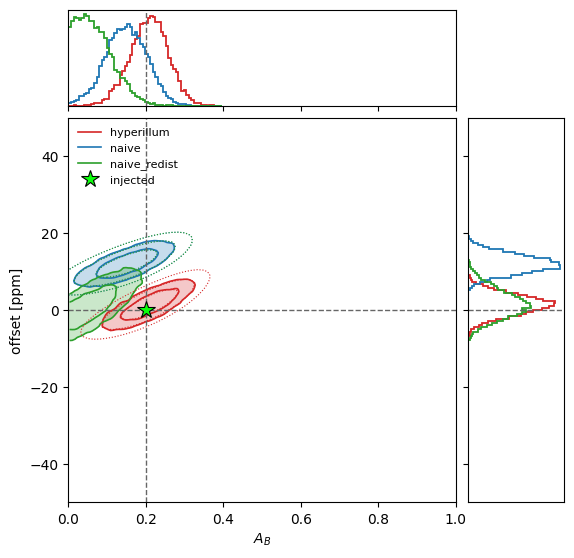

hyperillum   ESS 9135, information 4.37 nats
   A_B      =    0.2101 +0.0460 -0.0501   truth 0.2, bias +0.0101 = +0.21 sigma
   offset   =    1.4165 +2.6361 -2.7033   truth 0, bias +1.4165 = +0.53 sigma
   corr(A_B, offset) = +0.805
naive   ESS 9110, information 4.22 nats
   A_B      =    0.1500 +0.0526 -0.0532   truth 0.2, bias -0.0500 = -0.94 sigma
   offset   =   11.9157 +2.4953 -2.3949   truth 0, bias +11.9157 = +4.87 sigma
   corr(A_B, offset) = +0.751
naive_redist   ESS 9488, information 8.50 nats
   A_B      =    0.0619 +0.0538 -0.0414   truth 0.2, bias -0.1381 = -2.90 sigma
   offset   =    1.4531 +4.0224 -3.5018   truth 0, bias +1.4531 = +0.39 sigma
   F        =    0.0061 +0.0026 -0.0022   truth 0, bias +0.0061 = +2.51 sigma
   corr(A_B, offset) = +0.691
   corr(A_B, F) = -0.322
   corr(offset, F) = -0.777
ln B (hyperillum vs naive) = +6.244 +/- 0.077 (analytic) +/- 0.126 (jitter, K=200)  ->  B = 515
P(ln B > 0) = 1.000  [sampler noise only, NOT a model probability]
ln B (hyp

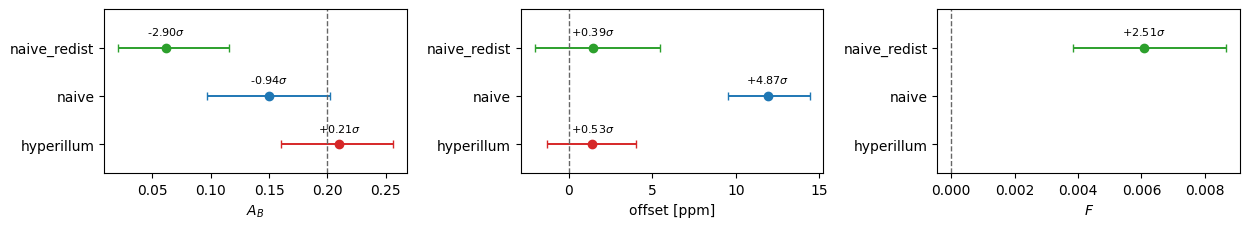

naive_redist: F < 0.0073 (68 %), F < 0.0105 (95 %)   [injected F = 0]


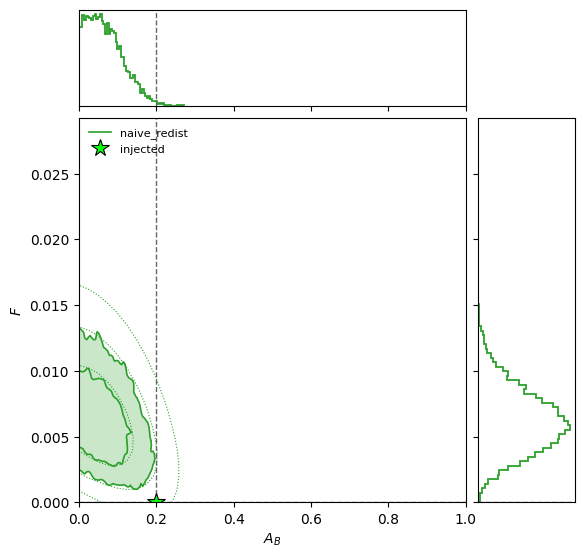

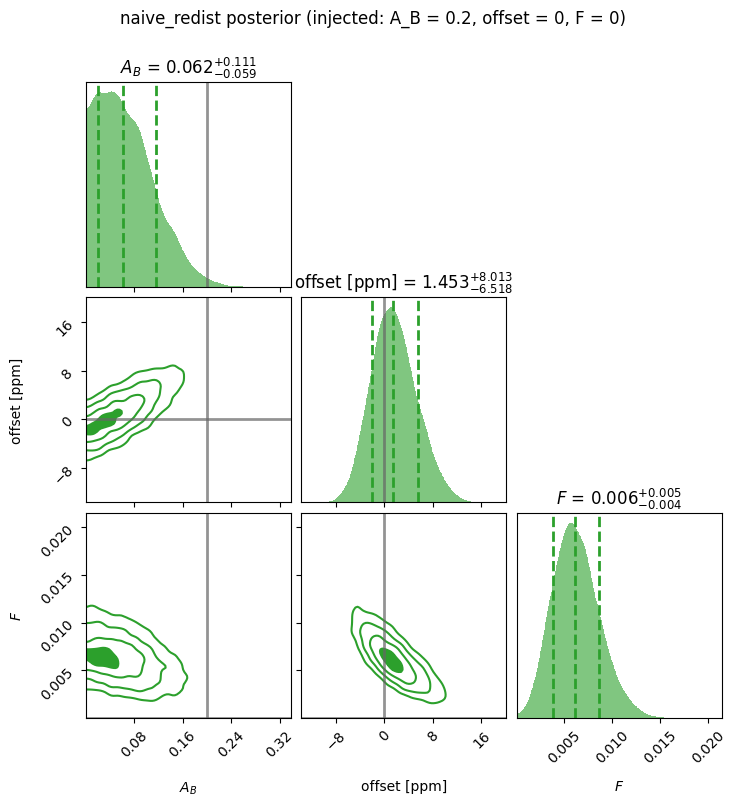

In [5]:
# Posterior, one (A_B, baseline) plane per baseline
for o in OFFSET_NAMES:
    profile = {name: (A_grid, O_grid, lnL) for name, (lnL, *_) in lnL_maps[o].items()}   # logl_grid returns (offset, A_B), which is what contour(A_grid, O_grid, ...) wants
    plot_posterior_overlay(fits, "A_B", o, truth=base, profile=profile, colors=COLOR)
    plt.show()

# Bayes Factor lnB
for f in fits.values(): posterior_summary(f, base)
# one Bayes factor per alternative present, each against the truth's own model
bfs = {m: bayes_factor(fits, INSOL_REF, m, K=200) for m in fits if m != INSOL_REF}

plot_bias(fits, base, colors=COLOR); plt.show()

# F-specific posteriors, whenever a loaded model samples it
for m in F_MODELS:   # one-sided against the F >= 0 prior: quote upper limits, not median +/- interval
    w, iF = fits[m].results.importance_weights(), PSETS[m].names.index("F")
    q68, q95 = dyfunc.quantile(fits[m].results.samples[:, iF], [0.68, 0.95], weights=w)
    print(f"{m}: F < {q68:.4f} (68 %), F < {q95:.4f} (95 %)   [injected F = {base['F']:g}]")
if F_MODELS:
    # the (A_B, F) plane: filled = the sampler's credible regions, dotted = the profile-likelihood contours of the map in 1.
    plot_posterior_overlay({m: fits[m] for m in F_MODELS}, "A_B", "F", truth=base,
                           profile={m: (A_gridF, F_gridF, lnL) for m, (lnL, *_) in lnL_maps_F.items()}, colors=COLOR)
    plt.show()

    # full corner: F against every other sampled parameter, from the equal-weight posterior
    for m in F_MODELS:
        fig, _ = dyplot.cornerplot(fits[m].results, labels=list(PSETS[m].labels), color=COLOR[m],
                                   truths=[base[n] for n in PSETS[m].names], truth_color="0.4",
                                   show_titles=True, title_fmt=".3f", quantiles=(0.16, 0.5, 0.84),
                                   fig=plt.subplots(PSETS[m].ndim, PSETS[m].ndim, figsize=(2.6 * PSETS[m].ndim,) * 2))
        fig.suptitle(f"{m} posterior (injected: " + ", ".join(f"{n} = {base[n]:g}" for n in PSETS[m].names) + ")", y=1.04)
        plt.show()

## 3. Posterior predictive: where in phase the evidence comes from

The posterior median curves of every model; below, for each alternative model against the truth's model, the difference of the median curves against $\pm\sigma_{\rm bin}$ and the per-bin $\Delta\chi^2$ between the best fits, which sums to $2\,\Delta\ln\mathcal{L}_{\max}$. Costs `N_DRAWS` forward models per model and figure.

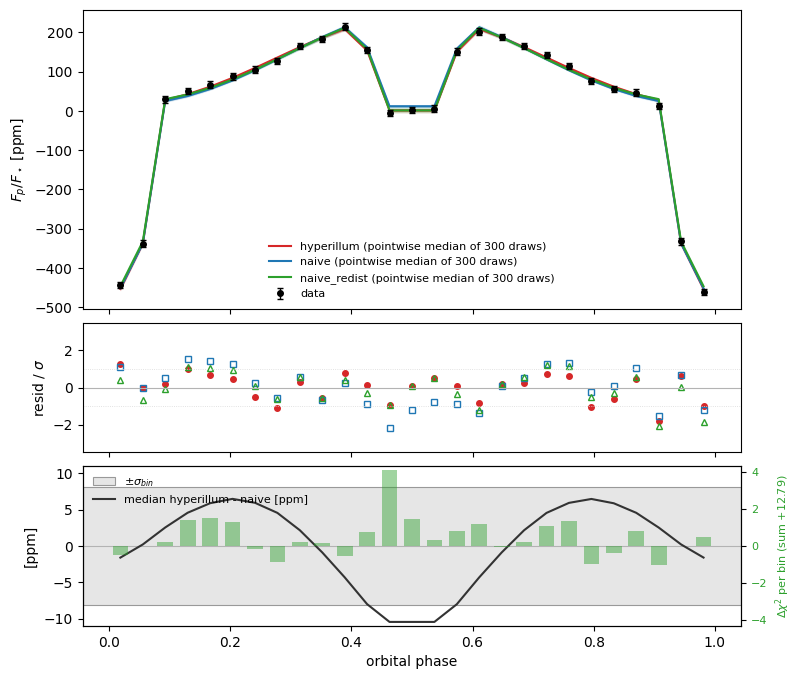

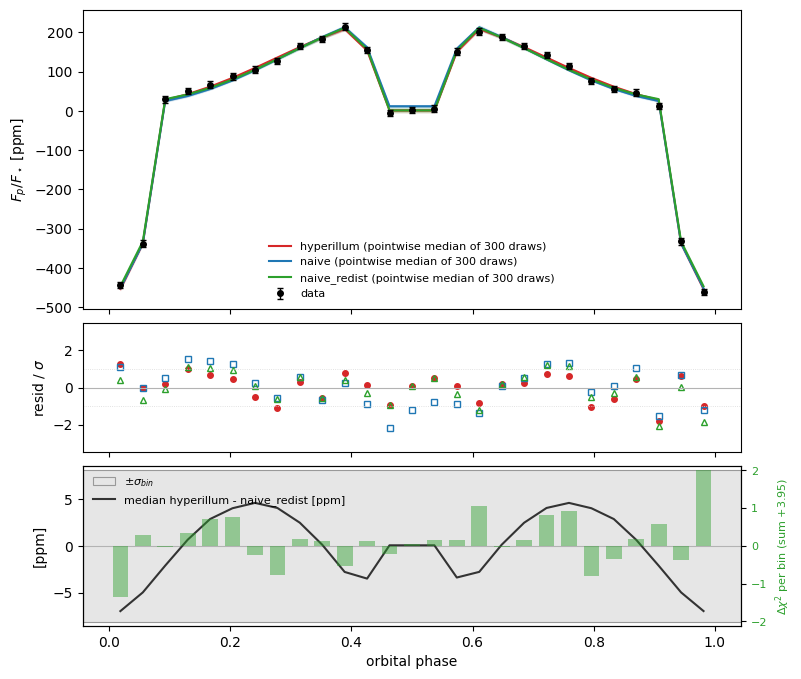

In [6]:
N_DRAWS = 300   # forward models per insolation model

for den in [m for m in fits if m != INSOL_REF]:   # panel 3 is pairwise: one figure per alternative, each against the truth's own model
    plot_posterior_predictive(logls, fits, num=INSOL_REF, den=den, n=N_DRAWS, colors=COLOR, n_jobs=N_JOBS)
    plt.show() # per-bin Δχ², computed as [(y−best_a)² − (y−best_b)²]/σ², so a bar is positive where model b fits that bin better.


## 4. Bias analysis

The posterior medians against the bias itself, the misspecified model fitted to the noiseless binned truth (`fit_naive`, or `fit_redist` with the false-positive $F$ and its nightside temperature), in units of the posterior width and of the Fisher $\sigma$. Lower panel: everything minus the truth against $\pm\sigma_{\rm bin}$; the dotted grey line is the numerical floor and should sit on zero.

NOISELESS fit(s) to the NOISELESS truth  (offset free, no noise, no seed - this is THE bias; the least-squares fits of the bias analysis):
   naive        A_B 0.1412   bias -0.0588 = -1.11 sigma_A_B (posterior, this seed) = -1.11 sigma_Fisher   ->   dT_sub/T = +1.79 %
                |dA_B|/sigma_A_B = 1.11   ->   sigma_1min,crit = 69.9 ppm (posterior) / 69.7 ppm (Fisher)   (now 62.9, already finer: the bias is a 1.1 sigma effect at the delivered noise)
                bias / floor = 12.693 / 0.001 = 14932.9x   ->   bias resolved
   naive_redist A_B 0.0314   bias -0.1686 = -3.54 sigma_A_B (posterior, this seed) = -2.39 sigma_Fisher   ->   dT_sub/T = +4.67 %
                F   0.0058   false positive (truth F = 0) = 2.42 sigma_F (posterior), sigma_F,Fisher = 0.0024 (one-sided at F = 0: indicative only)   ->   implied nightside T = 657 K
                |dA_B|/sigma_A_B = 3.54   ->   sigma_1min,crit = 222.8 ppm (posterior) / 150.5 ppm (Fisher)   (now 62.9, already finer: the bias is a 3

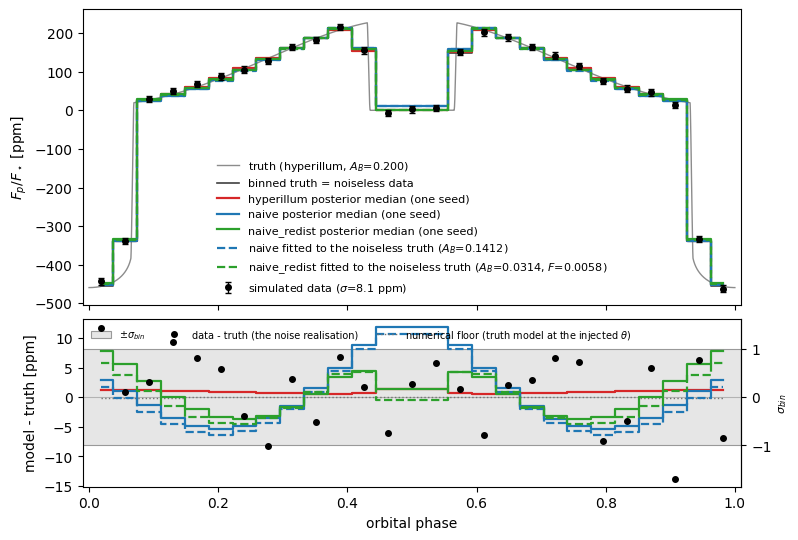

In [7]:
fig, _, out = plot_noisy_vs_truth(cfg, data, logls, fits, A_B_true, base, insolation_truth=INSOL_TRUTH,
                                  colors=COLOR)   # the noiseless fits (the bias) in A_B_FIT_BOUNDS, as in the bias analysis; one column per detector for a joint fit
plt.show()

## 5. Derived quantities

The posterior pushed through each model's own temperature map: substellar, terminator and antistellar temperature, occultation depth and dayside brightness temperature (per detector for a joint fit). The naive and hyperillum nightsides are exactly 0 K (`T_term` > 0 for naive is an interpolation artefact at 90°); the `naive_redist` one is what an observer would infer. The first lines check the occultation depth of `pcurve_params` against the maximum of the thermal phase curve. This section needs the NewEra cube (`inputs/stellar_model/NewEra/build_newera.ipynb`), the star of the stored runs.

      hyperillum   occultation_depth  232.30 ppm   phase-curve maximum  220.70 ppm
      naive        occultation_depth  228.19 ppm   phase-curve maximum  212.89 ppm
      naive_redist occultation_depth  228.19 ppm   phase-curve maximum  212.90 ppm
hyperillum         depth  237.5 +5.9 -4.9 ppm (thermal 231.2, reflected 6.3)   T_bright 2368.1 +40.0 -33.8 K
                   T_sub 2699.7 K   T_term 1508.1 K   T_anti    0.0 K
naive              depth  239.3 +5.6 -5.6 ppm (thermal 233.1, reflected 6.2)   T_bright 2381.2 +38.2 -38.3 K
                   T_sub 2733.4 K   T_term  551.9 K   T_anti    0.0 K
naive_redist       depth  248.4 +3.2 -5.0 ppm (thermal 242.2, reflected 6.2)   T_bright 2443.4 +21.5 -34.3 K
                   T_sub 2800.7 K   T_term  801.7 K   T_anti  663.9 K +61.9 -74.0 (< 761 K at 95 %)


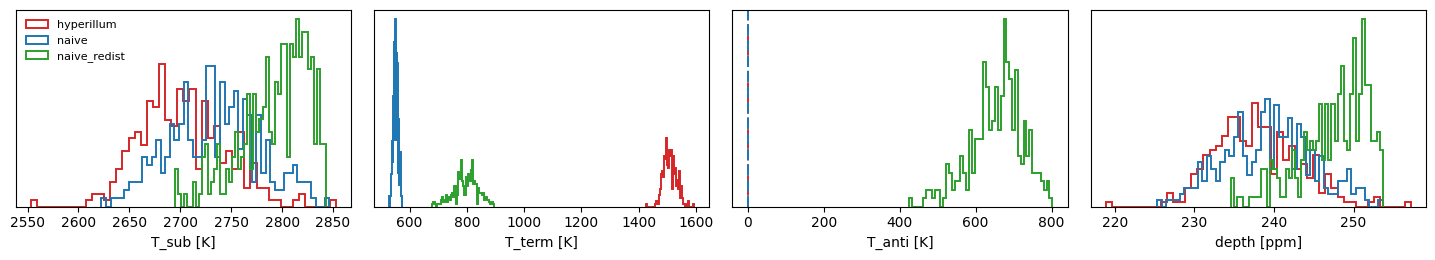

In [8]:
# Check of pcurve_params: for a thermal-only, transit-free config the occultation depth is close to the peak of the phase curve model_pcurve builds from the same sp.ModelParams
# (the maximum lies below the depth: at these a/R* the visible maximum sits at ingress, not at full phase).
for c, lab in zip(cfgs, LABELS or [""]):
    cfg_th = replace(c, reflected=False, transit=False)
    for m in fits:
        F_ = base["F"] if "F" in PSETS[m].names else None   # only "naive_redist" has one, and at the injected truth it is 0
        _, y_ = model_pcurve(cfg_th, m, A_B_true, F=F_, n_t=200 * c.n_bins)
        d_ = occultation_depth(pcurve_params(cfg_th, m, A_B_true, F=F_), stellar_grid=c.stellar_grid, emissivity=cfg_th.emissivity)
        print(f"{lab:5s} {m:12s} occultation_depth {d_:7.2f} ppm   phase-curve maximum {y_.max():7.2f} ppm")

der = {m: derived_samples(logls[m], equal_samples(fits[m], N_DRAWS, seed=0), n_jobs=N_JOBS) for m in fits}
SUF = [f":{lab}" for lab in LABELS] if JOINT else [""]          # the per-detector depth keys of a joint fit ("depth:NRS1", ...)
for name, d in der.items():
    for c, lab, suf in zip(cfgs, LABELS or [""], SUF):
        q, q_th = np.percentile(d["depth" + suf], [16, 50, 84]), np.percentile(d["depth_th" + suf], [16, 50, 84])
        Tb = brightness_temperature(d["depth_th" + suf], c)
        print(f"{name:12s} {lab:5s} depth {q[1]:6.1f} +{q[2]-q[1]:.1f} -{q[1]-q[0]:.1f} ppm (thermal {q_th[1]:.1f}, reflected {np.median(d['depth_refl' + suf]):.1f})   T_bright {Tb[1]:6.1f} +{Tb[2]-Tb[1]:.1f} -{Tb[1]-Tb[0]:.1f} K")
    Ta = np.percentile(d["T_anti"], [16, 50, 84, 95])
    print(f"{'':12s} {'':5s} T_sub {np.median(d['T_sub']):6.1f} K   T_term {np.median(d['T_term']):6.1f} K   T_anti {Ta[1]:6.1f} K" + (f" +{Ta[2]-Ta[1]:.1f} -{Ta[1]-Ta[0]:.1f} (< {Ta[3]:.0f} K at 95 %)" if name in F_MODELS else ""))

KEYS = ("T_sub", "T_term", *(("T_anti",) if F_MODELS else ()), *("depth" + suf for suf in SUF))   # the nightside only becomes a distribution with a redistributing model; one depth panel per detector
plot_derived(der, keys=KEYS, colors=COLOR); plt.show()
